# Model Evaluation and Architecture Comparison

This notebook evaluates and compares the Transformer, FNO, and hybrid architectures using the prediction files (`.npz`) generated by the training notebooks. The analysis includes performance metrics and comparisons across different noise conditions, sedimentation rates, and orbital component combinations.

## 1. Libraries and Dependencies

In [1]:
import json
import math
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, Subset, DataLoader
from sklearn.metrics import (f1_score, accuracy_score, hamming_loss,
                             label_ranking_loss, roc_auc_score)
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe


## 2. Evaluation Configuration

In [ ]:
# Paths to the dataset and prediction files.
DATA_DIR = Path("synthetic_dataset")
PRED_DIR = DATA_DIR / "predictions"

# Random seeds used across all architectures.
SEEDS = [0, 1, 2, 3, 4]

# False-positive rate and experimental conditions.
ALPHA = 0.05
NOISE_GROUP = "4"
NOISE_ORDER = ["no_noise", "n1", "n2", "n3"]
SR_MODES = ["constant", "trend", "step"]

# Architectures and display names.
ARCHITECTURES = ["transformer_only", "fno_only", "hybrid_concat"]
NAMES = {"transformer_only": "Transformer", "fno_only": "FNO",
         "hybrid_concat": "Hybrid"}

## 3. Dataset Loading

In [3]:
class CyclesDataset(Dataset):
    """Synthetic cyclostratigraphy series with multi-label targets.

    Expects an .npz holding `signals`, `depths`, `labels` and `label_names`,
    and a JSON list of per-series metadata aligned by index.
    """

    def __init__(self, npz_path, json_path):
        npz_path = Path(npz_path)
        json_path = Path(json_path)

        if not npz_path.exists():
            raise FileNotFoundError(f".npz file not found: {npz_path}")
        if not json_path.exists():
            raise FileNotFoundError(f".json file not found: {json_path}")

        npz_data = np.load(npz_path, allow_pickle=True)

        self.signals = npz_data["signals"]
        self.depths = npz_data["depths"]
        self.labels = npz_data["labels"]
        self.label_names = list(npz_data["label_names"])

        with open(json_path, "r", encoding="utf-8") as f:
            self.metadata = json.load(f)

        n_signals = self.signals.shape[0]
        n_meta = len(self.metadata)
        assert n_signals == n_meta, (
            f"Mismatch between .npz ({n_signals} series) and .json ({n_meta} entries). "
        )

    def __len__(self):
        return self.signals.shape[0]

    def __getitem__(self, idx: int):
        signal = torch.from_numpy(self.signals[idx]).float()
        depth = torch.from_numpy(self.depths[idx]).float()
        label = torch.from_numpy(self.labels[idx]).float()
        meta = self.metadata[idx]

        return {
            "signal": signal,
            "depth": depth,
            "label": label,
            "metadata": meta,
        }

## 4. Dataset Initialization

In [4]:
ds = CyclesDataset(
    npz_path=DATA_DIR / "synthetic_cyclostratigraphy_dataset.npz",
    json_path=DATA_DIR / "metadata.json",
)
LABELS = [str(n) for n in ds.label_names]
print(f"Total series: {len(ds)}")
print(f"Label order:  {ds.label_names}")

Total series: 25760
Label order:  [np.str_('precession'), np.str_('obliquity'), np.str_('E1'), np.str_('E2')]


## 5. Threshold Calibration and Test Prediction Loading

In [5]:
def calibrate(arch, seed, alpha=ALPHA):
    """Calibrate per-label thresholds using the (1 - alpha) quantile of
    predicted probabilities on pure-noise validation series.
    """
    d = np.load(PRED_DIR / f"{arch}_val_seed{seed}.npz", allow_pickle=True)
    noise = d["group"].astype(str) == NOISE_GROUP
    if noise.sum() == 0:
        raise ValueError(f"{arch} seed {seed}: no pure-noise series")
    return np.quantile(d["y_prob"][noise], 1 - alpha, axis=0)

def load_test(arch, seed, threshold=None):
    """Load test predictions and apply calibrated per-label thresholds.

    Pass threshold=0.5 to reproduce the uncalibrated baseline.
    """
    thr = calibrate(arch, seed) if threshold is None else threshold
    d = np.load(PRED_DIR / f"{arch}_test_seed{seed}.npz", allow_pickle=True)
    grupo = d["group"].astype(str)
    return {
        "y_true": d["y_true"], "y_prob": d["y_prob"],
        "bin": (d["y_prob"] >= thr).astype(int),
        "grupo": grupo, "pos": grupo != NOISE_GROUP,
        "noise": d["noise"].astype(str), "sr": d["sr"].astype(str),
        "combo": d["combo"].astype(str),
        "idx": d["idx"],
        "threshold": thr,
    }

# Display calibrated thresholds for each architecture and random seed.
for arch in ARCHITECTURES:
    print(f"Per-label threshold — {arch} (alpha={ALPHA})\n")
    L = []
    for s in SEEDS:
        thr = calibrate(arch, s)
        L.append(thr)
        print(f"seed {s}: " + "  ".join(f"{n}={t:.4f}"
                                        for n, t in zip(ds.label_names, thr)))
    L = np.array(L)
    print("\nmean across seeds:")
    for j, name in enumerate(ds.label_names):
        print(f"  {name:<13s} {L[:, j].mean():.4f} ± {L[:, j].std():.4f}")

Per-label threshold — transformer_only (alpha=0.05)

seed 0: precession=0.6649  obliquity=0.5517  E1=0.4594  E2=0.5363
seed 1: precession=0.4873  obliquity=0.5399  E1=0.4341  E2=0.5422
seed 2: precession=0.7434  obliquity=0.6230  E1=0.5581  E2=0.5632
seed 3: precession=0.6196  obliquity=0.5492  E1=0.4728  E2=0.4878
seed 4: precession=0.5940  obliquity=0.5205  E1=0.4413  E2=0.4627

mean across seeds:
  precession    0.6219 ± 0.0843
  obliquity     0.5568 ± 0.0348
  E1            0.4731 ± 0.0446
  E2            0.5184 ± 0.0372
Per-label threshold — fno_only (alpha=0.05)

seed 0: precession=0.7926  obliquity=0.7418  E1=0.6995  E2=0.5611
seed 1: precession=0.7321  obliquity=0.6543  E1=0.6479  E2=0.6513
seed 2: precession=0.8787  obliquity=0.6703  E1=0.7989  E2=0.6778
seed 3: precession=0.7368  obliquity=0.6974  E1=0.7603  E2=0.6519
seed 4: precession=0.7689  obliquity=0.6677  E1=0.6333  E2=0.6045

mean across seeds:
  precession    0.7818 ± 0.0532
  obliquity     0.6863 ± 0.0311
  E1      

## 6. Overall Performance Evaluation

In [6]:
def metrics(arch, seed, limiar=None):
    """Compute classification metrics and false-positive rates for one seed."""
    D = load_test(arch, seed, limiar)
    pos, yt, b, yp = D["pos"], D["y_true"], D["bin"], D["y_prob"]
    m = {
        "F1 macro": f1_score(yt[pos], b[pos], average="macro", zero_division=0),
        "F1 micro": f1_score(yt[pos], b[pos], average="micro", zero_division=0),
        "AUC-ROC macro": roc_auc_score(yt[pos], yp[pos], average="macro"),
        "Subset accuracy": accuracy_score(yt[pos], b[pos]),
        "Hamming loss": hamming_loss(yt[pos], b[pos]),
        "Ranking loss": label_ranking_loss(yt[pos], yp[pos]),
    }
    for nome, v in zip(ds.label_names,
                       f1_score(yt[pos], b[pos], average=None, zero_division=0)):
        m[f"F1 {nome}"] = v

    # Compute false-positive rates on pure-noise test series.
    for j, nome in enumerate(ds.label_names):
        m[f"[noise] FP {nome}"] = b[~pos, j].mean()
    m["[noise] >=1 FP"] = (b[~pos].sum(axis=1) > 0).mean()
    return m

# Summarize performance across seeds and architectures.
SUMMARY = {arch: [metrics(arch, s) for s in SEEDS] for arch in ARCHITECTURES}

print(f"Mean +/- sd over {len(SEEDS)} seeds, calibrated threshold "
      f"(alpha={ALPHA})\n")
header = f"{'metric':<26s}" + "".join(f"{NAMES[a]:>22s}" for a in ARCHITECTURES)
print(header)
print("-" * len(header))
for k in SUMMARY[ARCHITECTURES[0]][0]:
    line = f"{k:<26s}"
    for arch in ARCHITECTURES:
        v = np.array([m[k] for m in SUMMARY[arch]])
        line += f"{v.mean():>14.4f}+/-{v.std():.3f}"
    print(line)

Mean +/- sd over 5 seeds, calibrated threshold (alpha=0.05)

metric                               Transformer                   FNO                Hybrid
--------------------------------------------------------------------------------------------
F1 macro                          0.8322+/-0.006        0.8602+/-0.001        0.8673+/-0.003
F1 micro                          0.8323+/-0.006        0.8603+/-0.001        0.8674+/-0.003
AUC-ROC macro                     0.9467+/-0.003        0.9669+/-0.001        0.9689+/-0.000
Subset accuracy                   0.6465+/-0.011        0.6972+/-0.003        0.7100+/-0.006
Hamming loss                      0.1553+/-0.005        0.1273+/-0.001        0.1223+/-0.002
Ranking loss                      0.1302+/-0.005        0.0873+/-0.002        0.0901+/-0.003
F1 precession                     0.8498+/-0.008        0.8607+/-0.006        0.8646+/-0.007
F1 obliquity                      0.8330+/-0.008        0.8454+/-0.005        0.8510+/-0.008
F1 E1    

## 7. Pure-Noise Classification Performance

In [7]:
# Evaluate the proportion of pure-noise series with no false-positive detections.
header = f"{'architecture':<16s}{'subset acc':>20s}{'>=1 FP':>20s}"
print(header)
print("-" * len(header))

for arch in ARCHITECTURES:
    accs = []
    for s in SEEDS:
        D = load_test(arch, s)
        b = D["bin"][~D["pos"]]  # pure-noise group only
        accs.append((b.sum(axis=1) == 0).mean())
    accs = np.array(accs)
    print(f"{NAMES[arch]:<16s}"
          f"{accs.mean():>13.4f}+/-{accs.std():.3f}"
          f"{1 - accs.mean():>13.4f}+/-{accs.std():.3f}")

architecture              subset acc              >=1 FP
--------------------------------------------------------
Transformer            0.8542+/-0.019       0.1458+/-0.019
FNO                    0.8377+/-0.005       0.1623+/-0.005
Hybrid                 0.8468+/-0.012       0.1532+/-0.012


## 8. Performance by Noise Level

In [ ]:
def stratify_noise(arch):
    """Macro F1 by noise level, mean and standard deviation over seeds."""
    acc = {}
    for s in SEEDS:
        D = load_test(arch, s)
        col, pos = D["noise"], D["pos"]
        for v in np.unique(col[pos]):
            m = pos & (col == v)
            f1 = f1_score(D["y_true"][m], D["bin"][m],
                          average="macro", zero_division=0)
            acc.setdefault(v, []).append((f1, int(m.sum())))
    out = {v: (np.mean([x[0] for x in lst]),
               np.std([x[0] for x in lst]), lst[0][1])
           for v, lst in acc.items()}
    return {k: out[k] for k in NOISE_ORDER if k in out}


# Compare macro F1 across noise levels for all architectures.
for arch in ARCHITECTURES:
    print(f"{arch} - macro F1 by noise level\n")
    for v, (m, sd, n) in stratify_noise(arch).items():
        print(f"  {v:<12s} F1 = {m:.4f} +/- {sd:.4f}   (n={n})")
    print()

transformer_only - macro F1 by noise level

  no_noise     F1 = 0.9888 +/- 0.0017   (n=1405)
  n1           F1 = 0.9383 +/- 0.0108   (n=642)
  n2           F1 = 0.7534 +/- 0.0113   (n=644)
  n3           F1 = 0.3202 +/- 0.0330   (n=684)

fno_only - macro F1 by noise level

  no_noise     F1 = 0.9914 +/- 0.0008   (n=1405)
  n1           F1 = 0.9851 +/- 0.0015   (n=642)
  n2           F1 = 0.8475 +/- 0.0068   (n=644)
  n3           F1 = 0.2990 +/- 0.0241   (n=684)

hybrid_concat - macro F1 by noise level

  no_noise     F1 = 0.9969 +/- 0.0006   (n=1405)
  n1           F1 = 0.9887 +/- 0.0018   (n=642)
  n2           F1 = 0.8462 +/- 0.0137   (n=644)
  n3           F1 = 0.3389 +/- 0.0353   (n=684)



## 9. Performance by Noise Level and Sedimentation Rate

In [7]:
# Compare macro F1 across noise levels and sedimentation rate modes.
print(f"{'level':<10s}{'mode':<12s}" + "".join(f"{a:>22s}" for a in ARCHITECTURES))
print("-" * (22 + 22*len(ARCHITECTURES)))

for nv in NOISE_ORDER:
    for modo in SR_MODES:
        cels = []
        for arch in ARCHITECTURES:
            vals, n = [], 0
            for s in SEEDS:
                D = load_test(arch, s)
                m = D["pos"] & (D["noise"] == nv) & (D["sr"] == modo)
                if m.sum() == 0:
                    continue
                n = int(m.sum())
                vals.append(f1_score(D["y_true"][m], D["bin"][m],
                                     average="macro", zero_division=0))
            # Report the mean and standard deviation across random seeds.
            cels.append(f"{np.mean(vals):>14.4f}±{np.std(vals):.3f}"
                        if vals else f"{'—':>22s}")
        print(f"{nv:<10s}{modo:<12s}" + "".join(cels) + f"   (n={n})")


level     mode              transformer_only              fno_only         hybrid_concat
----------------------------------------------------------------------------------------
no_noise  constant            0.9913±0.002        0.9924±0.001        0.9977±0.001   (n=420)
no_noise  trend               0.9887±0.003        0.9973±0.001        0.9974±0.000   (n=512)
no_noise  step                0.9869±0.003        0.9842±0.002        0.9956±0.002   (n=473)
n1        constant            0.9504±0.011        0.9904±0.001        0.9945±0.003   (n=308)
n1        trend               0.9189±0.018        0.9862±0.002        0.9872±0.003   (n=159)
n1        step                0.9335±0.010        0.9739±0.004        0.9792±0.002   (n=175)
n2        constant            0.7589±0.012        0.8612±0.009        0.8558±0.016   (n=330)
n2        trend               0.7592±0.021        0.8502±0.005        0.8305±0.014   (n=155)
n2        step                0.7353±0.010        0.8111±0.011        0.8399±0

## 10. Per-Label Performance by Noise Level

In [ ]:
def stratify_noise(arch):
    """Macro F1 by noise level, mean and standard deviation over seeds."""
    acc = {}
    for s in SEEDS:
        D = load_test(arch, s)
        col, pos = D["noise"], D["pos"]
        for v in np.unique(col[pos]):
            m = pos & (col == v)
            f1 = f1_score(D["y_true"][m], D["bin"][m],
                          average="macro", zero_division=0)
            acc.setdefault(v, []).append((f1, int(m.sum())))
    out = {v: (np.mean([x[0] for x in lst]),
               np.std([x[0] for x in lst]), lst[0][1])
           for v, lst in acc.items()}
    return {k: out[k] for k in NOISE_ORDER if k in out}


# Compare macro F1 across noise levels for all architectures.
for arch in ARCHITECTURES:
    print(f"{arch} - macro F1 by noise level\n")
    for v, (m, sd, n) in stratify_noise(arch).items():
        print(f"  {v:<12s} F1 = {m:.4f} +/- {sd:.4f}   (n={n})")
    print()


transformer_only
nível             precession       obliquity              E1              E2
----------------------------------------------------------------------------
no_noise       0.9880±0.002   0.9936±0.003   0.9920±0.002   0.9817±0.002
n1             0.9457±0.004   0.9528±0.007   0.9480±0.010   0.9066±0.025
n2             0.7995±0.024   0.7283±0.025   0.7280±0.008   0.7577±0.010
n3             0.3711±0.036   0.3462±0.032   0.3593±0.054   0.2042±0.029

fno_only
nível             precession       obliquity              E1              E2
----------------------------------------------------------------------------
no_noise       0.9883±0.002   0.9859±0.002   0.9952±0.001   0.9963±0.001
n1             0.9808±0.003   0.9748±0.004   0.9916±0.001   0.9931±0.002
n2             0.8261±0.016   0.8130±0.007   0.8279±0.018   0.9230±0.004
n3             0.3655±0.031   0.2612±0.067   0.2622±0.042   0.3072±0.013

hybrid_concat
nível             precession       obliquity              E1     

## 11. Signal-to-Noise Ratio (SNR) Preparation

In [11]:
TOL, MIN_N = 0.15, 12


def full_snr():
    """Extract per-series, per-label SNR values from dataset metadata.

    NaN indicates an absent cycle or a series without noise.
    """
    S = np.full((len(ds.metadata), len(LABELS)), np.nan)
    for i, m in enumerate(ds.metadata):
        d = m.get("snr_per_cycle")
        if not d:
            continue
        for j, name in enumerate(LABELS):
            if name in d:
                S[i, j] = d[name]
    return S


def align_snr(S):
    """Align SNR values with test predictions using their original dataset indices."""
    d = np.load(PRED_DIR / f"{ARCHITECTURES[0]}_test_seed{SEEDS[0]}.npz",
                allow_pickle=True)
    if "idx" not in d.files or not d["idx"].size:
        raise RuntimeError(
            "Test .npz has no 'idx' field. Retrain to rewrite the predictions "
            "with 'idx'.")
    out = S[d["idx"]]
    n = d["y_true"].shape[0]
    assert out.shape[0] == n, f"SNR has {out.shape[0]} rows, test has {n}."
    return out


def matching_targets(S):
    """Identify reference SNR values for single-cycle series at each noise level."""
    targets = {}
    for i, m in enumerate(ds.metadata):
        level, combo = m.get("noise_level"), m["cycles_combo"]
        if level is None or len(combo) != 1:
            continue
        v = S[i, LABELS.index(combo[0])]
        previous = targets.setdefault(level, v)
        assert abs(previous - v) < 1e-9, (
            f"single-cycle SNR is not constant at {level}: "
            f"{previous:.6f} vs {v:.6f}")
    return targets


SNR_FULL = full_snr()
SNR = align_snr(SNR_FULL)
SNR_TARGET = matching_targets(SNR_FULL)

## 12. Detection Rates Across Cycle Combinations at Matched SNR

In [12]:
def matched_detection(level="n2", tol=TOL, min_n=MIN_N):
    """Compute per-label detection rates across cycle combinations.

    Multi-cycle series are restricted to an SNR window around the
    single-cycle reference at the selected noise level.
    Returns detection rates (mean and standard deviation across seeds),
    sample counts, and mean SNR for each combination and architecture.
    """
    target = SNR_TARGET[level]
    cache = {a: [load_test(a, s) for s in SEEDS] for a in ARCHITECTURES}
    D0 = cache[ARCHITECTURES[0]][0]
    out = {}

    for j, name in enumerate(LABELS):
        base = D0["pos"] & (D0["noise"] == level) & (D0["y_true"][:, j] == 1)
        combos = sorted(np.unique(D0["combo"][base]),
                        key=lambda c: (len(c.split("+")), c))
        rows = []
        for c in combos:
            rec = {"combo": c, "n": 0, "snr": np.nan}
            for arch in ARCHITECTURES:
                r, ns, snrs = [], [], []
                for D in cache[arch]:
                    m = D["pos"] & (D["noise"] == level) & (D["combo"] == c)
                    if len(c.split("+")) > 1:
                        m = m & (np.abs(SNR[:, j] - target) / target <= tol)
                    if m.sum() < min_n:
                        continue
                    r.append(D["bin"][m][:, j].mean())
                    ns.append(int(m.sum()))
                    snrs.append(np.nanmean(SNR[m, j]))
                rec[arch] = (np.mean(r), np.std(r)) if r else (np.nan, np.nan)
                if ns:
                    rec["n"] = int(np.mean(ns))
                    rec["snr"] = np.nanmean(snrs)
            rows.append(rec)
        out[name] = rows
    return out


MATCHED = matched_detection("n2")

## 13. Detection Rate Visualization Across Cycle Combinations

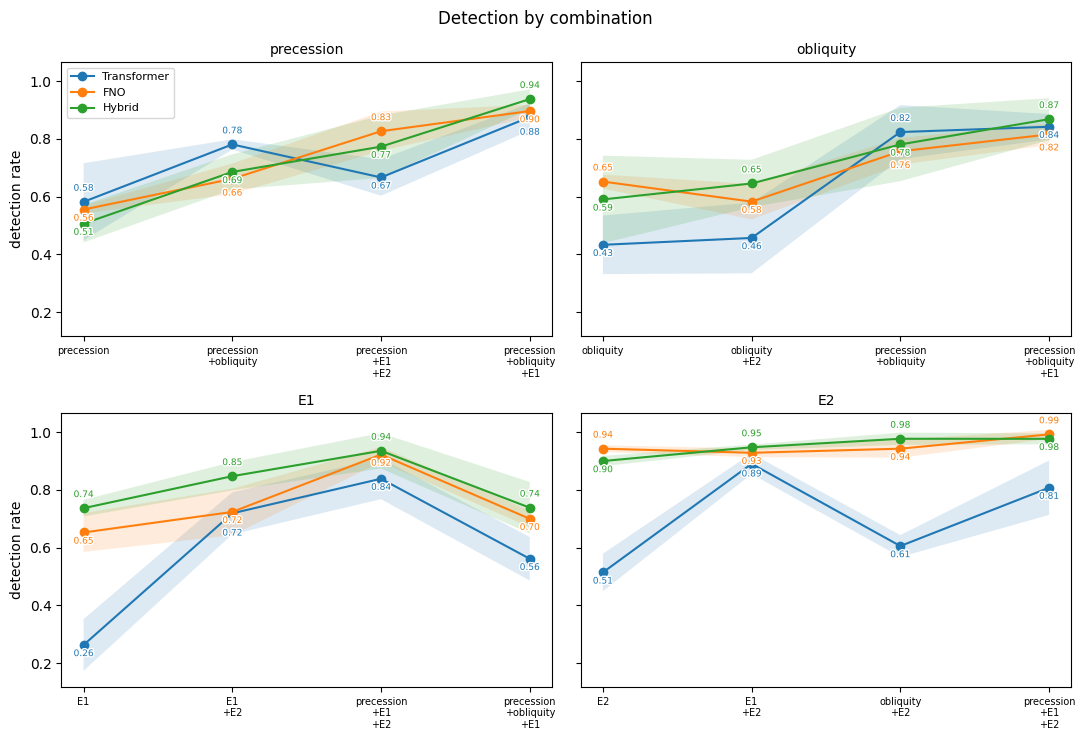

In [13]:
# Display names used only in the figure labels.
DISPLAY_NAMES = {
    "precessao": "Precession",
    "obliquidade": "Obliquity",
    "E1": "E1",
    "E2": "E2",
}

def translate_combo(combo):
    """Translate a '+'-joined combination string for display without changing the underlying data."""
    return "+".join(DISPLAY_NAMES.get(c, c) for c in combo.split("+"))

def matched_figure(res, level="n2", values=True, ylim=None):
    """Plot detection rates by cycle combination for each label and architecture.

    Mean values and standard deviations are shown across seeds, using the
    SNR-matched results previously computed for the selected noise level.
    """
    target = SNR_TARGET[level]
    fig, axs = plt.subplots(2, 2, figsize=(11, 7.5), sharey=True)

    if ylim is None:
        v = [r[a][0] for rows in res.values() for r in rows for a in ARCHITECTURES]
        v = [t for t in v if np.isfinite(t)]
        if v:
            span = max(v) - min(v)
            below = 0.20 if values else 0.05
            ylim = (min(v) - below * span, max(v) + 0.10 * span)
        else:
            ylim = (0, 1.05)

    axes = []
    for ax, (name, rows) in zip(axs.ravel(), res.items()):
        combos = [r["combo"] for r in rows]
        x = np.arange(len(combos))
        colors = {}
        for arch in ARCHITECTURES:
            y = np.array([r[arch][0] for r in rows])
            sd = np.array([r[arch][1] for r in rows])
            ln, = ax.plot(x, y, marker="o", label=NAMES[arch])
            ax.fill_between(x, y - sd, y + sd, alpha=0.15)
            colors[arch] = ln.get_color()
        ax.set_xticks(x)
        ax.set_xticklabels([translate_combo(c).replace("+", "\n+") for c in combos],
                           fontsize=7)
        ax.set_title(DISPLAY_NAMES.get(name, name), fontsize=10)
        ax.set_ylim(*ylim)
        axes.append((ax, rows, x, colors))

    axs[0, 0].set_ylabel("detection rate")
    axs[1, 0].set_ylabel("detection rate")
    axs[0, 0].legend(fontsize=8)
    fig.suptitle(f"Detection by combination")
    plt.tight_layout()

    # Optionally annotate each point with its mean detection rate.
    if values:
        fig.canvas.draw()
        px_to_pt = 72.0 / fig.dpi
        FONT = 6.5
        SEP = FONT + 2.5
        ABOVE = FONT + 1.5
        for ax, rows, x, colors in axes:
            for k in range(len(x)):
                items = [(a, rows[k][a][0]) for a in ARCHITECTURES
                         if np.isfinite(rows[k][a][0])]
                if not items:
                    continue
                items.sort(key=lambda t: t[1], reverse=True)
                py = [ax.transData.transform((x[k], v))[1] * px_to_pt
                      for _, v in items]
                targets = [py[0] + ABOVE]
                for i in range(1, len(items)):
                    targets.append(min(py[i] - ABOVE, targets[-1] - SEP))
                for (arch, v), yp, ya in zip(items, py, targets):
                    ax.annotate(f"{v:.2f}", (x[k], v),
                                textcoords="offset points", xytext=(0, ya - yp),
                                ha="center", fontsize=FONT, color=colors[arch],
                                annotation_clip=False, zorder=5,
                                path_effects=[pe.withStroke(linewidth=2.0,
                                                            foreground="white")])
    plt.show()

# Plot the matched-SNR detection-rate comparison.
matched_figure(MATCHED)

## 14. False-Positive Rates Between Orbital Labels

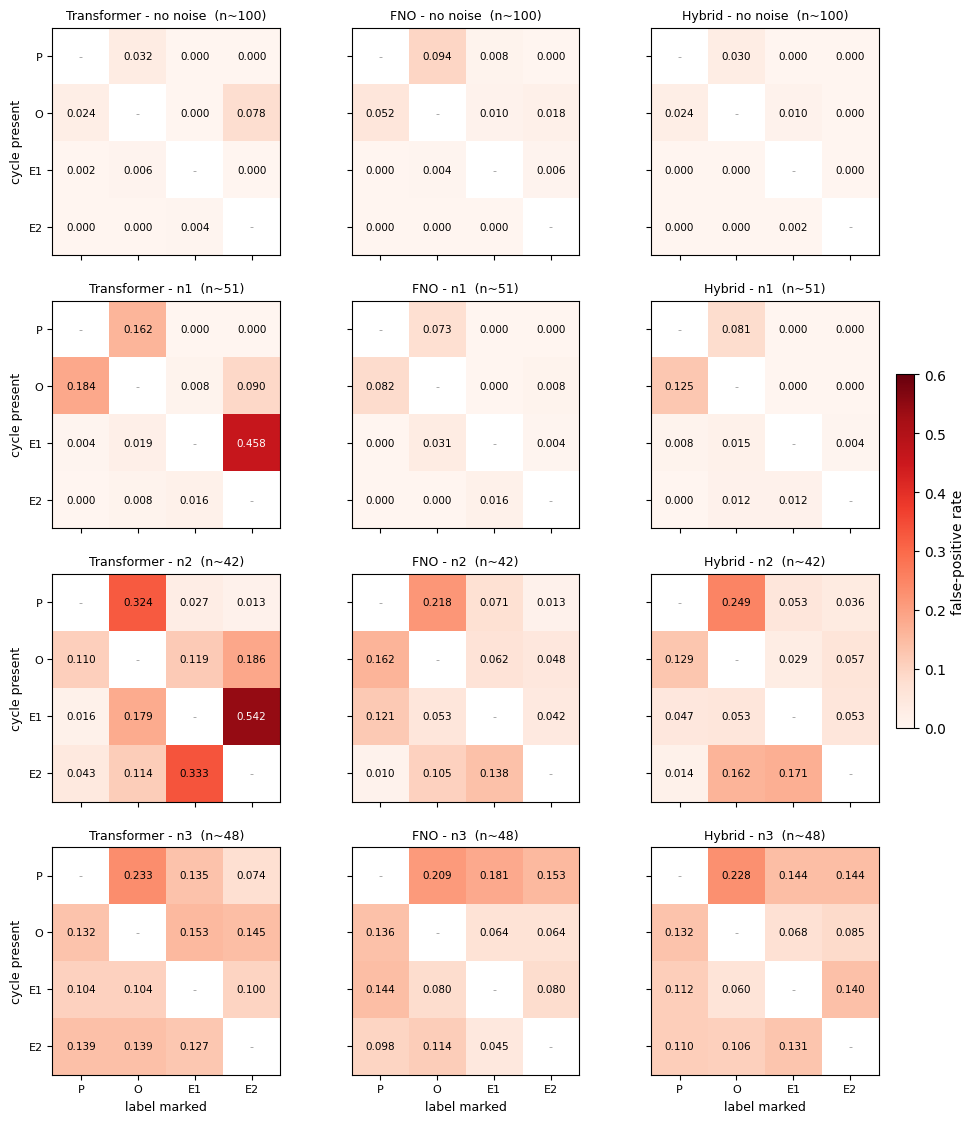

In [14]:
# Label abbreviations, display names, and architecture order.
SHORT = {"precession": "P", "obliquity": "O", "E1": "E1", "E2": "E2"}
NAMES = {"fno_only": "FNO", "transformer_only": "Transformer",
         "hybrid_concat": "Hybrid", "no_noise": "no noise"}
ARCH_ORDER = ["transformer_only", "fno_only", "hybrid_concat"]

SINGLES = tuple(LABELS)

# Retrieve ground-truth labels for single-cycle series.
_D0 = load_test(ARCH_ORDER[0], SEEDS[0])
TRUE_VEC = {c: _D0["y_true"][_D0["pos"] & (_D0["combo"] == c)][0]
            for c in SINGLES}


def false_positive_figure(levels=("no_noise", "n1", "n2", "n3"),
                          singles=SINGLES, vmax=0.6):
    """Plot false-positive rates between orbital labels for single-cycle series.

    Rows represent noise levels and columns represent architectures.
    Each cell shows the mean false-positive rate across seeds for an
    absent label, given the presence of the cycle indicated by its row.
    """
    archs = [a for a in ARCH_ORDER
             if (PRED_DIR / f"{a}_test_seed{SEEDS[0]}.npz").exists()]
    cache = {a: [load_test(a, s) for s in SEEDS] for a in archs}
    n_lab = len(LABELS)

    fig, axs = plt.subplots(len(levels), len(archs), squeeze=False,
                            figsize=(3.8 * len(archs), 3.4 * len(levels)))

    for r, level in enumerate(levels):
        for c, arch in enumerate(archs):
            Ds = cache[arch]
            M = np.full((len(singles), n_lab), np.nan)

            # Compute false-positive rates only for absent labels.
            for i, combo in enumerate(singles):
                for j in range(n_lab):
                    if TRUE_VEC[combo][j]:
                        continue
                    vals = [D["bin"][m][:, j].mean() for D in Ds
                            if (m := D["pos"] & (D["combo"] == combo)
                                & (D["noise"] == level)).sum()]
                    if vals:
                        M[i, j] = np.mean(vals)

            counts = [int((Ds[0]["pos"] & (Ds[0]["combo"] == combo)
                           & (Ds[0]["noise"] == level)).sum())
                      for combo in singles]
            n_cell = int(np.median(counts))

            ax = axs[r, c]
            im = ax.imshow(np.ma.masked_invalid(M), vmin=0, vmax=vmax,
                           cmap="Reds", aspect="equal")
            for i in range(len(singles)):
                for j in range(n_lab):
                    if np.isfinite(M[i, j]):
                        ax.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center",
                                fontsize=7.5,
                                color="white" if M[i, j] > 0.35 else "black")
                    else:
                        ax.text(j, i, "-", ha="center", va="center",
                                fontsize=8, color="#999999")

            ax.set_xticks(range(n_lab))
            if r == len(levels) - 1:
                ax.set_xticklabels([SHORT[c_] for c_ in LABELS], fontsize=8)
                ax.set_xlabel("label marked", fontsize=9)
            else:
                ax.set_xticklabels([])

            ax.set_yticks(range(len(singles)))
            ax.set_yticklabels([SHORT[c_] for c_ in singles] if c == 0
                               else [""] * len(singles), fontsize=8)
            if c == 0:
                ax.set_ylabel("cycle present", fontsize=9)

            ax.set_title(f"{NAMES.get(arch, arch)} - {NAMES.get(level, level)}"
                         f"  (n~{n_cell})", fontsize=9)

    fig.colorbar(im, ax=axs, label="false-positive rate",
                 fraction=0.02, pad=0.02)
    plt.show()


false_positive_figure()

## 15. Spectral Analysis of Synthetic Orbital Signals

[All Series Lengths (2500-5000 kyr)] precession     peak at mode  190  (n=200)
[All Series Lengths (2500-5000 kyr)] obliquity      peak at mode   91  (n=200)
[All Series Lengths (2500-5000 kyr)] E1             peak at mode   28  (n=200)
[All Series Lengths (2500-5000 kyr)] E2             peak at mode   10  (n=200)
[Series Length 3625-3875 kyr] precession     peak at mode  157  (n=25)
[Series Length 3625-3875 kyr] obliquity      peak at mode   91  (n=22)
[Series Length 3625-3875 kyr] E1             peak at mode   39  (n=20)
[Series Length 3625-3875 kyr] E2             peak at mode    9  (n=14)


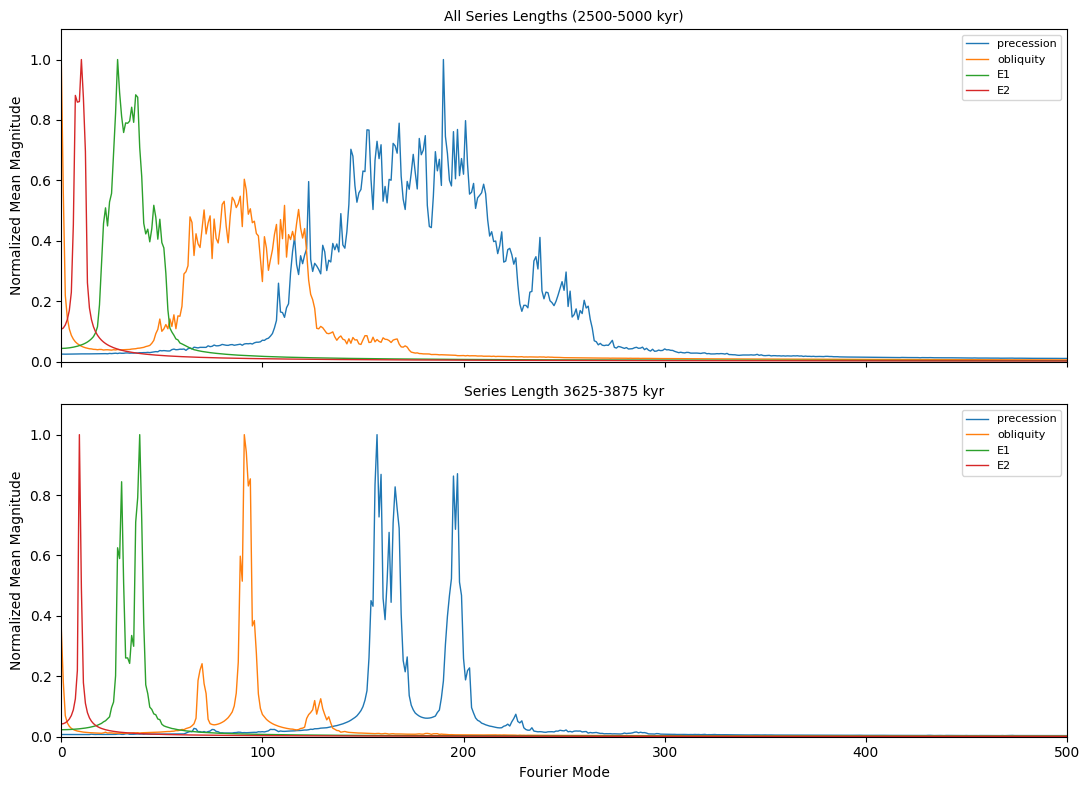

In [15]:
# Extract signals, labels, and metadata for spectral analysis.
signals = ds.signals
labels = ds.labels

group = np.array([str(m["group"]) for m in ds.metadata])
length = np.array([m["length_kyr"] for m in ds.metadata])

clean = group == "0"               # clean signal, constant sedimentation rate
single = labels.sum(axis=1) == 1   # exactly one cycle present

# Select a narrower series-length interval for spectral comparison.
L_TARGET, L_TOL = 3750.0, 125.0
in_band = np.abs(length - L_TARGET) < L_TOL

DISPLAY_NAMES = {
    "precessao": "Precession",
    "obliquidade": "Obliquity",
    "E1": "E1",
    "E2": "E2",
}

fig, axs = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
panels = [
    (axs[0], clean & single, "All Series Lengths (2500-5000 kyr)"),
    (axs[1], clean & single & in_band,
     f"Series Length {L_TARGET - L_TOL:.0f}-{L_TARGET + L_TOL:.0f} kyr"),
]

# Compute normalized mean Fourier spectra for each orbital component.
for ax, base, title in panels:
    for i, name in enumerate(LABELS):
        sel = base & (labels[:, i] == 1)
        if sel.sum() < 10:
            print(f"[{title}] {name}: only {sel.sum()} series, curve omitted")
            continue
        spectrum = np.abs(np.fft.rfft(signals[sel], axis=-1)).mean(axis=0)
        spectrum = spectrum / spectrum.max()
        peak = int(np.argmax(spectrum[1:]) + 1)
        print(f"[{title}] {name:14s} peak at mode {peak:4d}  (n={sel.sum()})")
        label = DISPLAY_NAMES.get(name, name)
        ax.plot(spectrum, lw=1, label=label)

    ax.set_xlim(0, 500)
    ax.set_ylim(0, 1.10)
    ax.set_ylabel("Normalized Mean Magnitude")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)

axs[1].set_xlabel("Fourier Mode")
plt.tight_layout()
plt.show()